# A6 crop stress model: training and evaluation

Trains the stress models step by step: climatology, Ridge, LightGBM, Optuna-tuned LightGBM, quantile and bootstrap intervals, SHAP and permutation importance. It saves the outputs to `data/processed/models/a6/` and logs the run. The formulas are tested functions in `model/stress.py` and `model/stress_pipeline.py`.

Validation is leave-one-year-out and senatorial-zone folds, never random splits. Write-up: `docs/model-results.md`.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import experiments, stress
from model import stress_pipeline as sp
from model.experiments import log_experiments
from model.io import load_tables, write_csv, write_json
from model.settings import load_model_config

## 1. Load data and build the training table

In [4]:
# Build the training table: within-LGA weather anomalies plus static soil and cropland
# columns (features) and the August to September cropland NDVI anomaly (target). Kaduna
# North and South are dropped (too little cropland). Rows: 21 LGAs x 25 years.
cfg = load_model_config()
sm = cfg.stress_model
year, month, static = load_tables(cfg.paths.features_dir, cfg)
data = sp.prepare(year, month, static, cfg)
x, y = data.x, data.y
years = data.train["year"].to_numpy()
zones = data.train["zone"].to_numpy()
{
    "training matrix": x.shape,
    "target": sm.target,
    "years": f"{years.min()} to {years.max()}",
    "LGAs": data.train["lga"].nunique(),
}

{'training matrix': (525, 16),
 'target': 'target_train_z',
 'years': '2000 to 2024',
 'LGAs': 21}

Features are within-LGA weather anomalies plus three static soil and cropland columns. The target is the LGA's peak cropland greenness anomaly. SMAP is missing before 2015: LightGBM takes the NaN, Ridge gets 0 plus a missing indicator.

## 2. One fold by hand, to show what each model is

In [5]:
# One fold by hand, to show what each model is: hold out 2017, fit Ridge (alpha chosen by
# RidgeCV) and LightGBM (tree count from early stopping on training years) on the other 24
# years, and compare their RMSE with predicting 0, the LGA's normal.
held_out = 2017
te = years == held_out
alphas = np.logspace(sm.ridge_alphas.log10_min, sm.ridge_alphas.log10_max, sm.ridge_alphas.count)

# Ridge: standardize, then Ridge with alpha chosen by efficient leave-one-out CV.
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas))
ridge.fit(stress.ridge_matrix(x[~te]), y[~te])

# LightGBM: shallow trees, tree count from early stopping on held-out training years.
params = dict(sm.lightgbm)
trees = stress.early_stopped_trees(
    x[~te],
    y[~te],
    years[~te],
    params,
    sm.early_stopping_rounds,
    sm.early_stopping_min_trees,
    sm.early_stopping_year_share,
    cfg.random_seed,
)
booster = lgb.LGBMRegressor(**{**params, "n_estimators": trees}, random_state=cfg.random_seed)
booster.fit(x[~te], y[~te])


def rmse(pred: np.ndarray) -> float:
    return float(mean_squared_error(y[te], pred) ** 0.5)


pd.Series(
    {
        "climatology (predict 0)": rmse(np.zeros(te.sum())),
        f"Ridge (alpha {ridge[-1].alpha_:.0f})": rmse(ridge.predict(stress.ridge_matrix(x[te]))),
        f"LightGBM ({trees} trees)": rmse(booster.predict(x[te])),
    },
    name=f"RMSE, held-out year {held_out} ({te.sum()} LGAs)",
).round(3)

climatology (predict 0)    0.955
Ridge (alpha 203)          0.753
LightGBM (70 trees)        0.703
Name: RMSE, held-out year 2017 (21 LGAs), dtype: float64

**One fold proves nothing.** 2017 was a statewide bad year (greenness z about -0.8), and both models catch it. Section 4 runs all 25 held-out years: averaged over them, neither model beats predicting normal. This is why the standards forbid judging a model on a single split.

## 3. Tune LightGBM with Optuna (40 trials, year-grouped CV)

In [6]:
# Tune LightGBM with Optuna: 40 trials over tree depth, learning rate, tree count and
# regularization, each scored by 5-fold CV grouped by year. Section 10 checks how much this
# flatters the tuned model.
optuna.logging.set_verbosity(optuna.logging.WARNING)
tuned, tuned_rmse = stress.tune_lgbm(x, y, years, params, sm.optuna_trials, cfg.random_seed)
{
    "best CV RMSE during tuning": round(tuned_rmse, 4),
    "tuned settings": {k: v for k, v in tuned.items() if params.get(k) != v},
}

{'best CV RMSE during tuning': 1.0037,
 'tuned settings': {'num_leaves': 12,
  'min_child_samples': 59,
  'learning_rate': 0.011127708190443111,
  'n_estimators': 21,
  'colsample_bytree': 0.8015395975159688,
  'reg_lambda': 0.013223621386250427}}

Optuna is scored on the same years it is later validated on, so the tuned model's scores are an optimistic upper bound.

## 4. Train and validate every model: leave-one-year-out and senatorial-zone folds

In [7]:
# The real validation: refit every model in every fold, under two schemes. Leave-one-year-
# out holds out all 21 LGAs of one year; senatorial-zone holds out a block of LGAs for all
# years. Never random splits: neighbouring LGAs and the same year share weather.
settings = sp.cv_settings(cfg, tuned)
n_folds = {
    "leave_one_year_out": LeaveOneGroupOut().get_n_splits(groups=years),
    "senatorial_zone": LeaveOneGroupOut().get_n_splits(groups=zones),
}
# Per fold: Ridge, LightGBM, tuned LightGBM, two quantile LightGBMs and the bootstrap Ridge refits.
cv = sp.validate(data, settings)
metrics, coverage = sp.summarise_cv(cv, sm.quantiles)
metrics.round(3)

,scheme,model,n,rmse,mae,skill_vs_climatology,corr
0,leave_one_year_out,climatology,525,0.980,0.777,0.000,NaN
1,leave_one_year_out,ridge,525,1.019,0.819,-0.040,-0.016
2,leave_one_year_out,lgbm,525,1.042,0.842,-0.064,-0.046
3,leave_one_year_out,lgbm_tuned,525,0.988,0.785,-0.009,-0.093
4,senatorial_zone,climatology,525,0.980,0.777,0.000,NaN
5,senatorial_zone,ridge,525,1.032,0.825,-0.054,0.025
6,senatorial_zone,lgbm,525,1.004,0.807,-0.025,0.158
7,senatorial_zone,lgbm_tuned,525,0.976,0.774,0.004,0.092


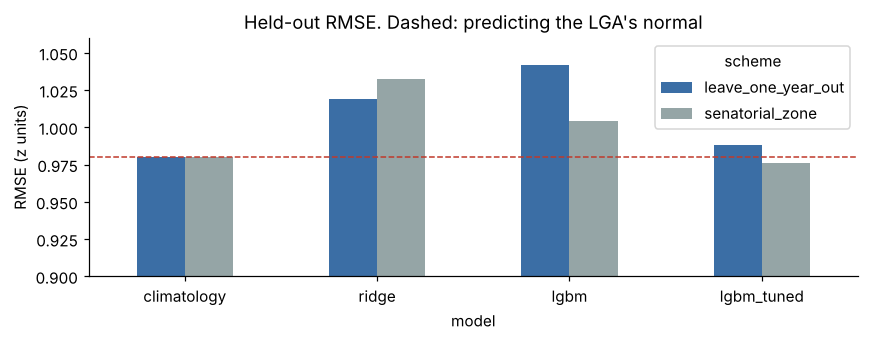

In [8]:
# Compare held-out RMSE across models and schemes. Anything above the dashed line is worse
# than predicting each LGA's normal.
table = metrics.pivot(index="model", columns="scheme", values="rmse").loc[
    ["climatology", "ridge", "lgbm", "lgbm_tuned"]
]
ax = table.plot.bar(figsize=(8, 3.2), color=["#3b6ea5", "#95a5a6"], rot=0)
ax.axhline(table.loc["climatology"].iloc[0], ls="--", color="#c0392b", lw=1)
ax.set_ylim(0.9, 1.06)
ax.set_ylabel("RMSE (z units)")
ax.set_title("Held-out RMSE. Dashed: predicting the LGA's normal")
plt.tight_layout()

## 5. Interval coverage (an 80% range should hold about 80% of outcomes)

In [9]:
# Interval coverage: an 80% range should contain about 80% of held-out outcomes.
coverage.round(3)

,scheme,interval,coverage,mean_width
0,leave_one_year_out,lgbm_quantile,0.695,2.216
1,leave_one_year_out,ridge_bootstrap,0.718,2.348
2,leave_one_year_out,ridge_loyo_residual,0.798,2.676
3,senatorial_zone,lgbm_quantile,0.657,1.878
4,senatorial_zone,ridge_bootstrap,0.722,2.291
5,senatorial_zone,ridge_loyo_residual,0.802,2.676


## 6. Apply the honesty rule

In [10]:
# Honesty rule: ship a model only if it beats climatology by at least min_skill (config).
# Otherwise Ridge is kept as a documented baseline and cards use weather risk instead.
decision = sp.ship_decision(metrics, sm.min_skill)
decision

{'shipped': 'ridge',
 'lgbm_beats_ridge': False,
 'has_skill': False,
 'skill_loyo': -0.04,
 'skill_zone': -0.054,
 'card_source': 'weather_risk_a2_a9'}

LightGBM did not beat Ridge, and neither beats predicting normal. Ridge ships as the documented baseline only; card stress lines come from weather risk (A2 dry spells, A9 water fit), not from A6.

## 7. Why: the weather signal is between years, not between LGAs

,feature,label,r_pooled,r_between_years,r_within_year,loyo_skill
9,season_chirps_heavy_days_50mm,very heavy rain days,-0.121,-0.389,-0.033,-0.010
3,a2_dry_spells_10plus,10+ day dry spells,-0.141,-0.334,-0.076,-0.006
12,season_smap_anomaly_z,"soil moisture (SMAP, 2015 on)",-0.100,-0.219,0.004,-0.018
2,a2_longest_dry_spell_days,longest dry spell,-0.083,-0.117,-0.074,-0.015
4,rain_early_mm,May-June rain,-0.007,-0.042,0.019,-0.018
0,a2_onset_doy,rain start date,0.043,0.053,0.038,-0.018
10,season_imerg_extreme_days_p95,extreme rain days,-0.034,0.061,-0.095,-0.016
7,season_power_heat_days,heat days,0.054,0.072,0.056,-0.021
11,water_balance_mid_mm,July-August water balance,0.079,0.213,-0.021,-0.021
6,rain_late_mm,September-October rain,0.080,0.257,-0.112,-0.021


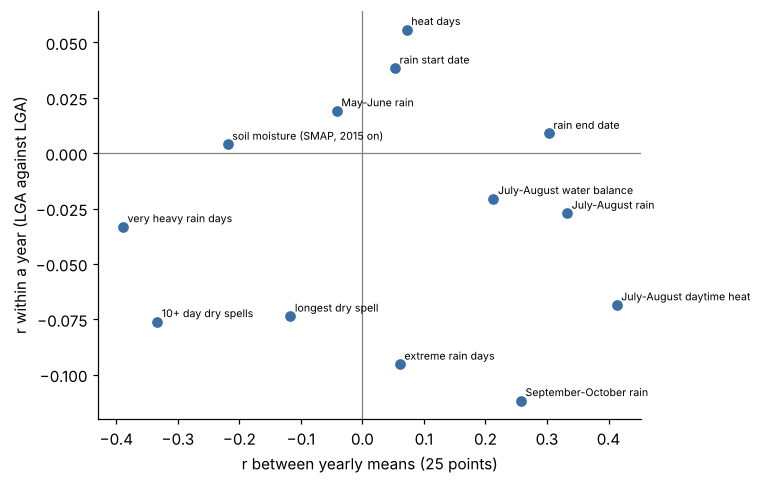

In [11]:
# Why no skill: correlate each feature with the target between years (25 yearly means) and
# within a year (LGA against LGA). The signal that exists is statewide, not local.
diag = stress.signal_diagnostics(x[list(sm.weather_features)], y, years)
diag.insert(1, "label", diag["feature"].map(sm.labels))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(diag["r_between_years"], diag["r_within_year"], color="#3b6ea5")
for _, row in diag.iterrows():
    ax.annotate(
        row["label"],
        (row["r_between_years"], row["r_within_year"]),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points",
    )
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("r between yearly means (25 points)")
ax.set_ylabel("r within a year (LGA against LGA)")
plt.tight_layout()
diag.sort_values("r_between_years").round(3)

## 8. Final models on all rows, and what they lean on (SHAP and permutation importance)

,label,ridge_shap_share,lgbm_shap_share,shipped_permutation_share
tmax_mid_c,July-August daytime heat,0.221,0.246,0.345
a2_cessation_doy,rain end date,0.149,0.095,0.178
a2_dry_spells_10plus,10+ day dry spells,0.126,0.063,0.136
rain_mid_mm,July-August rain,0.110,0.063,0.105
a2_onset_doy,rain start date,0.065,0.065,0.025
season_power_heat_days,heat days,0.063,0.232,0.034
season_chirps_heavy_days_50mm,very heavy rain days,0.062,0.014,0.078
season_smap_anomaly_z,"soil moisture (SMAP, 2015 on)",0.054,0.029,0.045
season_imerg_extreme_days_p95,extreme rain days,0.053,0.031,0.028
rain_early_mm,May-June rain,0.038,0.038,0.018


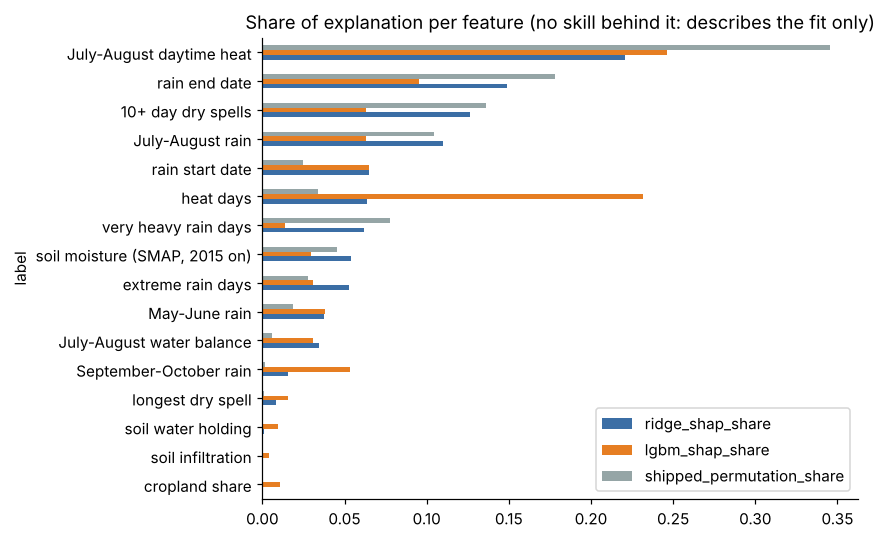

In [12]:
# Final models fitted on every training row, then what they lean on: SHAP shares for Ridge
# and LightGBM, and permutation importance for the shipped model.
final = sp.final_models(data, settings, decision["shipped"])
tree_values = np.asarray(shap.TreeExplainer(final["lgbm"]).shap_values(x))
importance = sp.importance(final, data, cfg)
ax = (
    importance.set_index("label")[
        ["ridge_shap_share", "lgbm_shap_share", "shipped_permutation_share"]
    ]
    .iloc[::-1]
    .plot.barh(figsize=(8, 5), color=["#3b6ea5", "#e67e22", "#95a5a6"])
)
ax.set_title("Share of explanation per feature (no skill behind it: describes the fit only)")
plt.tight_layout()
importance.round(3)

## 9. Expected stress per LGA and season type, beside the observed record

In [13]:
# Expected stress for every LGA under each A5 season type, beside the observed record of
# that LGA in years of that type. Scope: all 23 LGAs (21 modelled, 2 flagged low cropland).
types = pd.read_csv(cfg.paths.output_dir / "a5" / "a5_lga_year_types.csv")
resid = sp.residual_range(cv, decision["shipped"], sm.quantiles)
scenario_table = sp.scenarios(data, types, final, resid, decision, cfg)
scenario_table.groupby("season_type")[
    ["expected_stress_z", "observed_mean_z", "observed_share_stressed"]
].mean().round(2)

,expected_stress_z,observed_mean_z,observed_share_stressed
season_type,,,
Dry spell,-0.07,-0.02,0.29
Late start,0.28,0.25,0.24
Short and dry,-0.21,-0.22,0.37
Typical,0.03,0.09,0.25


## 10. Leakage checks

Three ways information could leak from the held-out years into training, each tested by rerunning leave-one-year-out with that path closed. If a score drops when a leak is closed, the shipped score was inflated by it.

1. **LGA normals.** Target and feature anomalies are measured against each LGA's mean over all 25 years, so the held-out year is 1/25 of its own normal. Rerun with normals from the training years only.
2. **Target in the features.** Shuffle the target: no honest model can then beat climatology. A score above 0 would mean the target leaked into the inputs.
3. **Tuning.** Optuna in section 3 saw every year. Rerun with Optuna inside each fold, tuned on the training years only.

In [14]:
# Leak 1, LGA normals: rerun leave-one-year-out Ridge with target and feature normals from
# the training years only, and compare its skill with the shipped pipeline's.
infold = stress.infold_anomaly_cv(
    data.train, "target_peak_ndvi_crop", list(sm.weather_features), list(sm.static_features), alphas
)
loyo = cv[cv["scheme"] == "leave_one_year_out"]
leak_rows = [
    {
        "check": "LGA normals from all years (shipped)",
        "model": "ridge",
        "skill": stress.skill_vs_climatology(loyo["target"].to_numpy(), loyo["ridge"].to_numpy()),
    },
    {
        "check": "LGA normals from training years only",
        "model": "ridge",
        "skill": stress.skill_vs_climatology(infold["y"].to_numpy(), infold["ridge"].to_numpy()),
    },
]
pd.DataFrame(leak_rows).round(4)

,check,model,skill
0,LGA normals from all years (shipped),ridge,-0.0403
1,LGA normals from training years only,ridge,-0.0125


In [15]:
# Leak 2, target in the features: shuffle the target 20 times and rerun. With no real link
# left, skill must sit at or below 0; a positive score would expose a leak.
shuffled = stress.shuffled_target_skill(x, y, years, alphas, sm.shuffle_runs, cfg.random_seed)
leak_rows.append(
    {
        "check": f"shuffled target, median of {sm.shuffle_runs} runs",
        "model": "ridge",
        "skill": float(np.median(shuffled)),
    }
)
{"shuffled-target skill, 5th and 95th percentile": np.percentile(shuffled, [5, 95]).round(4)}

{'shuffled-target skill, 5th and 95th percentile': array([-0.0059, -0.001 ])}

In [16]:
# Leak 3, tuning: rerun Optuna inside every leave-one-year-out fold (training years only)
# and compare with the tuned model scored on years Optuna had already seen.
nested = stress.nested_tuned_cv(x, y, years, params, sm.nested_optuna_trials, cfg.random_seed)
leak_rows += [
    {
        "check": "Optuna tuned on all years (shipped)",
        "model": "lgbm_tuned",
        "skill": stress.skill_vs_climatology(
            loyo["target"].to_numpy(), loyo["lgbm_tuned"].to_numpy()
        ),
    },
    {
        "check": "Optuna tuned inside each fold",
        "model": "lgbm_tuned",
        "skill": stress.skill_vs_climatology(y, nested),
    },
]
leakage = pd.DataFrame(leak_rows)
leakage.round(4)

,check,model,skill
0,LGA normals from all years (shipped),ridge,-0.0403
1,LGA normals from training years only,ridge,-0.0125
2,"shuffled target, median of 20 runs",ridge,-0.0021
3,Optuna tuned on all years (shipped),lgbm_tuned,-0.0086
4,Optuna tuned inside each fold,lgbm_tuned,-0.0147


**Reading.** No leak creates skill. Closing the normals leak moves Ridge's skill by about 0.03, and it stays below 0. Shuffled targets score about 0, as they must. Nested tuning lowers the tuned model's skill a little (about -0.009 to -0.015), confirming the shipped tuned score was slightly flattered. Every model stays at or below climatology either way, so the decision in section 6 stands.

## 11. Save the outputs and log the run

In [17]:
# Write every A6 table (including the leakage checks) and the run summary, then log the
# four models to docs/experiments.csv.
out = cfg.paths.output_dir / "a6"
tables = {
    "a6_cv_predictions": cv,
    "a6_metrics": metrics,
    "a6_interval_coverage": coverage,
    "a6_diagnostics": diag,
    "a6_lga_season_type_stress": scenario_table,
    "a6_feature_importance": importance.reset_index(names="feature"),
    "a6_lga_drivers": sp.lga_drivers(final, data, sm.labels).reset_index(names="lga"),
    "a6_leakage_checks": leakage,
}
for name, table in tables.items():
    write_csv(table, out / f"{name}.csv")
summary = sp.summarise(data, decision, (tuned, tuned_rmse), final, resid, diag, params)
write_json(summary, out / "a6_summary.json")
log_experiments(
    cfg.paths.experiment_log, experiments.a6_rows(summary, metrics, cfg, experiments.today())
)
sorted(p.name for p in out.iterdir())

['a6_cv_predictions.csv',
 'a6_diagnostics.csv',
 'a6_feature_importance.csv',
 'a6_interval_coverage.csv',
 'a6_leakage_checks.csv',
 'a6_lga_drivers.csv',
 'a6_lga_season_type_stress.csv',
 'a6_metrics.csv',
 'a6_summary.json']